# Retail Sales Analysis - Simple Version
**Data Analyst Internship - StarCentauri Technologies**

**Aim:** find out how the shop is doing - sales, profit, customers - and what it should do.

**Note:** the data file is a *sample* file (not real company data).

## 1. Look at the data
**What we do:** open the file and check what is wrong in it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/raw/retail_sales_raw.csv")
print("rows and columns:", df.shape)
df.head()

rows and columns: (9989, 19)


,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Market_Segment,Region,State,City,Product_ID,Category,Sub_Category,Product_Name,Unit_Price,Quantity,Discount,Sales,Profit
0,ORD-2023-00001,2023-01-01,2023-01-02,First Class,C-0070,Kavita Banerjee,Consumer,West,Rajasthan,Jaipur,P-1052,Office Supplies,Binders,Deluxe Binder,840.0,2,0.12,1478.4,385.89
1,ORD-2023-00001,2023-01-01,2023-01-02,First Class,C-0070,Kavita Banerjee,Consumer,West,Rajasthan,Jaipur,P-1111,Technology,Accessories,Pro Accessory,4490.0,2,0.17,7453.4,640.92
2,ORD-2023-00002,2023-01-01,2023-01-01,Same Day,C-0016,Neha Joshi,Consumer,Central,Madhya Pradesh,Bhopal,P-1053,Office Supplies,Binders,Smart Binder,900.0,6,0.00,5400.0,2084.67
3,ORD-2023-00002,2023-01-01,2023-01-01,Same Day,C-0016,Neha Joshi,Consumer,Central,Madhya Pradesh,Bhopal,P-1092,Office Supplies,Storage,Deluxe Storage Box,3230.0,1,0.05,3068.5,582.26
4,ORD-2023-00002,2023-01-01,2023-01-01,Same Day,C-0016,Neha Joshi,Consumer,Central,Madhya Pradesh,Bhopal,P-1023,Furniture,Furnishings,Pro Furnishing Set,400.0,4,0.00,1600.0,477.85


In [2]:
print("duplicate rows:", df.duplicated().sum())
df.isnull().sum()

duplicate rows: 100


Order_ID           0
Order_Date         8
Ship_Date          0
Ship_Mode         46
Customer_ID        0
Customer_Name      0
Market_Segment     0
Region            66
State              0
City               0
Product_ID         0
Category           0
Sub_Category       0
Product_Name       0
Unit_Price         0
Quantity           0
Discount          87
Sales              0
Profit             0

**What we found:** the file has 100 duplicate rows, some empty cells, and the same word written in different ways
(for example `TECHNOLOGY`, `technology`, `west`, `West `). Sales and Order_Date are also saved as text. We fix all this in the next part.

## 2. Clean the data
**What we do:** fix the problems one by one. Each line has a small note.

In [3]:
rows_before = len(df)

df = df.drop_duplicates()                                  # remove repeated rows

df['Category'] = df['Category'].str.strip().str.title()    # same spelling
df['Category'] = df['Category'].replace({'Office Supply': 'Office Supplies', 'Furnitures': 'Furniture'})
df['Region'] = df['Region'].str.strip().str.title()

df['Sales'] = pd.to_numeric(df['Sales'].astype(str).str.replace(',', ''))      # text -> number
df['Order_Date'] = pd.to_datetime(df['Order_Date'], format='mixed', errors='coerce')   # text -> date

In [4]:
# remove rows with no date, and rows with a date after Dec 2025 (not possible)
df = df.dropna(subset=['Order_Date'])
df = df[df['Order_Date'] <= '2025-12-31']

In [5]:
# fill empty cells
df['Discount'] = df['Discount'].fillna(df['Discount'].median())
df['Ship_Mode'] = df['Ship_Mode'].fillna(df['Ship_Mode'].mode()[0])
city_region = df.dropna(subset=['Region']).groupby('City')['Region'].first()
df['Region'] = df['Region'].fillna(df['City'].map(city_region))      # region comes from the city

In [6]:
# some sales have a wrong minus sign. Sales = Quantity x Price x (1 - Discount)
wrong = df['Sales'] < 0
df.loc[wrong, 'Sales'] = df['Quantity'] * df['Unit_Price'] * (1 - df['Discount'])

print("rows before:", rows_before)
print("rows after :", len(df))
print("empty cells left:", df.isnull().sum().sum())
df.to_csv("data/cleaned/cleaned_retail_sales.csv", index=False)

rows before: 9989
rows after : 9872
empty cells left: 0


**What we did:** removed duplicates and wrong dates, made the spelling same, changed text to numbers/dates, filled empty cells, and fixed the minus sign.
The file went from 9,989 rows to 9,872 rows. The clean file is saved in `data/cleaned/`.

## 3. Total sales and profit
**What we do:** add up Sales and Profit, and check each year.

In [7]:
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.strftime('%Y-%m')

total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
print("Total sales :", round(total_sales))
print("Total profit:", round(total_profit))
print("Profit % of sales:", round(total_profit / total_sales * 100, 1))
print()
print(df.groupby('Year')['Sales'].sum().round())

Total sales : 127693127
Total profit: 16428488
Profit % of sales: 12.9

Year
2023    31955361.0
2024    41424603.0
2025    54313163.0
Name: Sales, dtype: float64


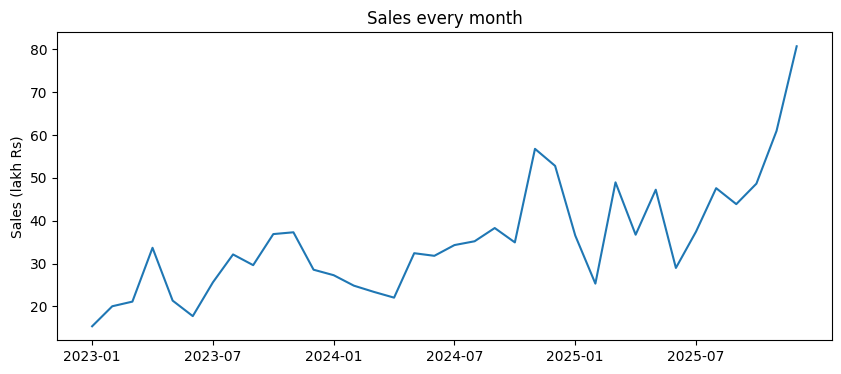

In [8]:
monthly = df.groupby('Month')['Sales'].sum() / 100000

plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values)
plt.xticks(range(0, len(monthly), 6), monthly.index[::6])
plt.title('Sales every month')
plt.ylabel('Sales (lakh Rs)')
plt.savefig('charts/1_monthly_sales.png')
plt.show()

**In simple words:** sales grow every year (about 30% in 2024 and 31% in 2025) and are highest in the last months of the year.

## 4. Which category and region is best?
**What we do:** group the data by Category and by Region. Margin = Profit / Sales x 100.

                      Sales      Profit  Margin %
Category                                         
Furniture        27745831.8    -10236.6      -0.0
Office Supplies  28500808.5   5411199.7      19.0
Technology       71446487.0  11027524.7      15.4


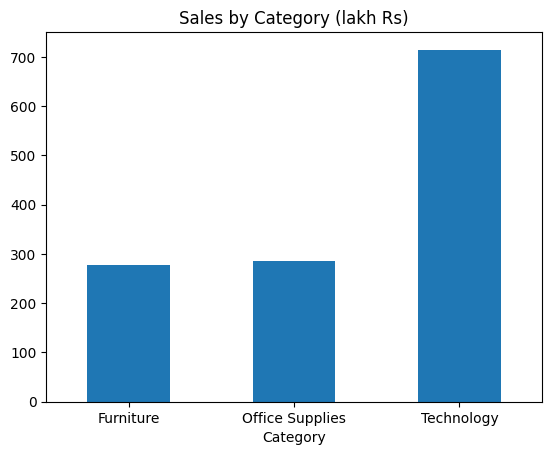

In [9]:
cat = df.groupby('Category')[['Sales', 'Profit']].sum()
cat['Margin %'] = cat['Profit'] / cat['Sales'] * 100
print(cat.round(1))

(cat['Sales'] / 100000).plot(kind='bar', title='Sales by Category (lakh Rs)', rot=0)
plt.savefig('charts/2_category.png')
plt.show()

              Sales     Profit  Margin %  Avg discount %
Region                                                  
Central  14146514.0  1883195.0      13.3             7.9
East     12453237.5  1694751.4      13.6             8.1
North    30634853.5  4195931.3      13.7             7.6
South    36982183.0  4994283.9      13.5             7.5
West     33476339.3  3660326.1      10.9            11.0


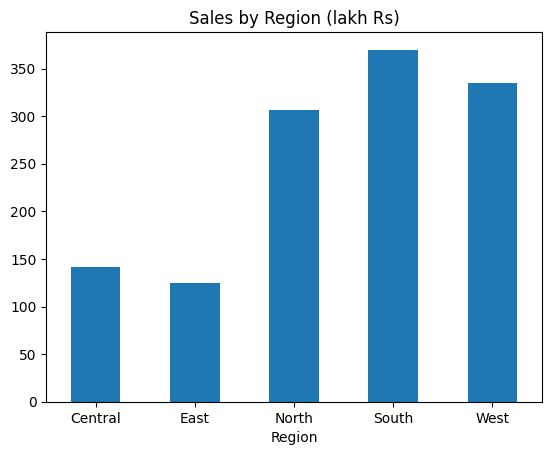

In [10]:
reg = df.groupby('Region')[['Sales', 'Profit']].sum()
reg['Margin %'] = reg['Profit'] / reg['Sales'] * 100
reg['Avg discount %'] = df.groupby('Region')['Discount'].mean() * 100
print(reg.round(1))

(reg['Sales'] / 100000).plot(kind='bar', title='Sales by Region (lakh Rs)', rot=0)
plt.savefig('charts/3_region.png')
plt.show()

**In simple words:**
- **Technology** gives the most sales (56% of all sales).
- **Furniture** has almost no profit (margin -0.04%).
- **South** has the most sales, but **West** has the lowest profit margin (10.9%). West also gives the highest discount.

## 5. Does discount reduce profit?

In [11]:
big = df[df['Discount'] > 0.20]
small = df[df['Discount'] <= 0.20]
print("profit % when discount is above 20%:", round(big['Profit'].sum() / big['Sales'].sum() * 100, 1))
print("profit % when discount is 20% or less:", round(small['Profit'].sum() / small['Sales'].sum() * 100, 1))

profit % when discount is above 20%: -27.3
profit % when discount is 20% or less: 17.2


**In simple words:** yes. When discount is more than 20% the shop makes a **loss** (-27.3% margin).

## 6. Customers and products

In [12]:
cust = df.groupby('Customer_ID').agg(Sales=('Sales', 'sum'), Orders=('Order_ID', 'nunique'))
print("customers:", len(cust))
print("customers who bought more than once:", (cust['Orders'] > 1).sum())
print("top 5 customers:")
print(cust.sort_values('Sales', ascending=False).head(5).round())

customers: 754
customers who bought more than once: 567
top 5 customers:
                 Sales  Orders
Customer_ID                   
C-0930       2943695.0     102
C-0787       2628185.0      85
C-0080       2516082.0      74
C-0120       2128846.0      65
C-0074       2032220.0      76


In [13]:
prod = df.groupby('Product_Name')[['Sales', 'Profit']].sum().sort_values('Sales', ascending=False)
print("top 5 products:")
print(prod.head(5).round())
print()
print("products that make a loss:", (prod['Profit'] < 0).sum(), "out of", len(prod))

top 5 products:
                    Sales     Profit
Product_Name                        
Pro Phone       8471628.0  1165500.0
Premium Phone   6191536.0  1068127.0
Eco Phone       5665780.0  1031802.0
Classic Copier  4548146.0  1255336.0
Deluxe Phone    4311218.0   662042.0

products that make a loss: 32 out of 136


**In simple words:** 75% of customers buy again, and they give 95% of the sales. Some products lose money: Bookcases, Machines, Supplies, Tables are the loss-making groups.

## 7. SQL (same answer using SQL)

In [14]:
import sqlite3
con = sqlite3.connect(':memory:')
df.to_sql('sales', con, index=False)

print(pd.read_sql_query("SELECT SUM(Sales) AS total_sales, SUM(Profit) AS total_profit FROM sales", con))
print(pd.read_sql_query("SELECT Category, SUM(Sales) AS total_sales FROM sales GROUP BY Category", con))

   total_sales  total_profit
0  127693127.3   16428487.74
          Category  total_sales
0        Furniture   27745831.8
1  Office Supplies   28500808.5
2       Technology   71446487.0


SQL gives the same total as Pandas, so our answer is correct.

## 8. Main numbers (KPIs)

In [15]:
orders = df['Order_ID'].nunique()
print("Total sales     :", round(total_sales))
print("Total profit    :", round(total_profit))
print("Total orders    :", orders)
print("Total customers :", df['Customer_ID'].nunique())
print("Average order   :", round(total_sales / orders))

Total sales     : 127693127
Total profit    : 16428488
Total orders    : 4396
Total customers : 754
Average order   : 29048


## 9. Conclusion
1. Sales are growing every year (31% in 2025).
2. Technology gives most of the sales.
3. Furniture and the West region have the lowest profit margin.
4. Discount above 20% makes a loss - **keep a limit on discount**.
5. Most customers buy again - **look after them**.
6. Some products lose money (Bookcases, Machines, Supplies, Tables) - **change their price or stop them**.

*Limitation: sample data, only 3 years (2023 to 2025).*